#### Notebook for comparing the cnoidal waves with the waves from the Newton solver

In [2]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [3]:
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from solvers.help import *
from waves.soliton import kdv_cnoidal


import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.special import ellipj, ellipk, ellipe
from scipy.optimize import brentq

In [4]:
# Wave parameters

N = 2**7
amp = 1
mean = 0
P = 16
c1 = Camera(P,N,1)

In [5]:
#Creating a newton wave
wp = KdVNewton(P,amp, mean, c1)
wp.solve_w_continuation()
phi_newton = wp.get_physical(wp.phi_hat_mid)

In [6]:
# then the cnoidal wave

phi_cn, c_cn, m = kdv_cnoidal(
    P = wp.P,
    crest=amp, 
    mean = mean,
    x = c1.x,
    t=0
)

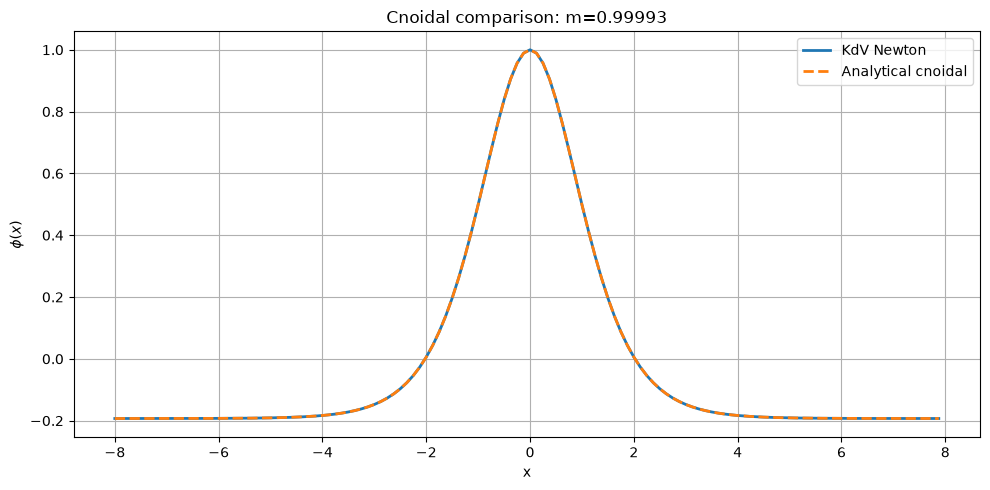

Newton wave speed:    1.2046060759
Cnoidal wave speed:   1.2046060759
Maximum profile error: 1.529e-11
RMS profile error:     4.260e-12


In [7]:
# Plotting them
plt.figure(figsize=(10, 5))
plt.plot(c1.x, phi_newton, label="KdV Newton", linewidth=2)
plt.plot(c1.x, phi_cn[0], "--", label="Analytical cnoidal", linewidth=2)
plt.xlabel("x")
plt.ylabel(r"$\phi(x)$")
plt.title(f"Cnoidal comparison: m={m:.5f}")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Newton wave speed:    {wp.c:.10f}")
print(f"Cnoidal wave speed:   {c_cn:.10f}")
print(f"Maximum profile error: "
      f"{np.max(np.abs(phi_newton - phi_cn[0])):.3e}")
print(f"RMS profile error:     "
      f"{np.sqrt(np.mean((phi_newton - phi_cn[0])**2)):.3e}")

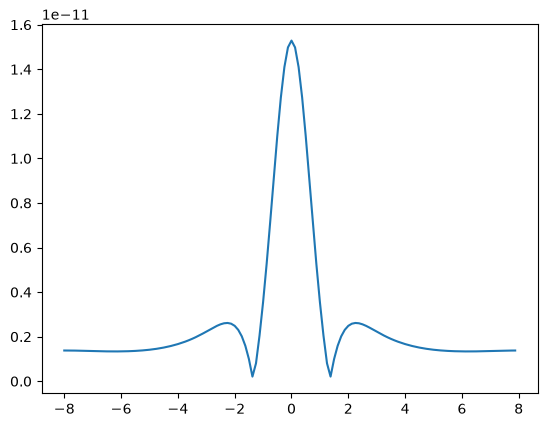

In [8]:
plt.plot(c1.x, np.abs(phi_newton-phi_cn[0]));

c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Lib\site-packages\matplotlib\cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\henri\Documents\progging\Prosjekt_Master\.venv\Lib\site-packages\matplotlib\cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


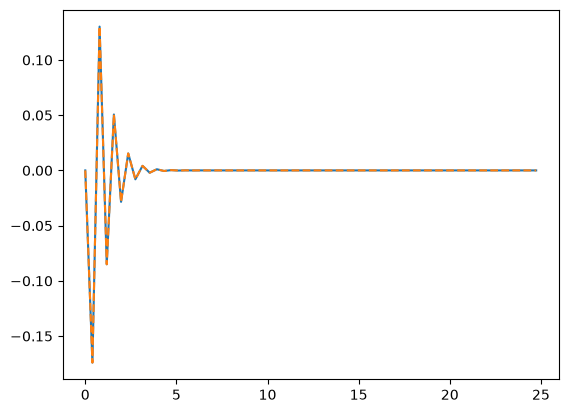

In [ ]:
plt.plot(c1.k[:c1.N//2], wp.phi_hat_mid[:-1], label = "Newton");
plt.plot(c1.k[:c1.N//2], np.fft.rfft(phi_cn[0])[:-1]/c1.N, '--', label = "Cnoidal");

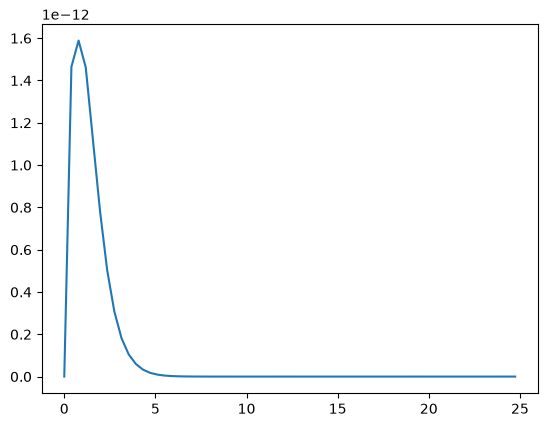

In [43]:
plt.plot(c1.k[:c1.N//2],np.abs(wp.phi_hat_mid[:-1] - np.fft.rfft(phi_cn[0])[:-1]/c1.N) , label = "diff");

We can then look at the forward solver and compare it to the analytical cnoidal wave

In [9]:
# Wave parameters
P = 16
N = 2**7
dt = 5e-3

c2 = Camera(P,N,dt)

T = 1
amp = 1
mean = 0

In [10]:
# Newton wave and solver
nw = KdVNewton(P,amp,mean,c2)
nw.solve_w_continuation()
nw_phi = nw.get_physical(nw.phi_hat_mid)

ns = KdV(c2, T, u0=nw_phi)
t,ns_phi = ns.ifrk4()

In [11]:
# Cnoidal wave
cn_phi, c_cn, m = kdv_cnoidal(P, amp, mean,c2.x,t)

In [12]:
# animate_solution_nb(c2.x, ns_phi)

In [13]:
# animate_solution_nb(c2.x, cn_phi)

In [19]:
animate_solution_nb(c2.x, cn_phi-ns_phi)

As we can see from the plots, the numerical solver and the analytical cn wave give similar values over the time steps. 

However, we can see that there is some radiation in the numerical sovler, the sacale is small and can be neglected. 

In comparing the split step solver with the ifrk4 one finds that the latter has an error 1e-4 lower than SS. at dt = 1e-3

Values of N greater than 2**7 does not seem to improve the errors, might hit the Newton limit. 
- Changing newton limit from 1e-13 to 1e-15 did not impact the limit in N

Values of dt greater than 1e-3 gives fluctuations in the error, for 1e-3 it is smooth and looks like radiation from KdV

In [15]:
# Let us now compare the solver to the true forward solution
# Using the cn wave from above
cn_f = KdV(c2, T, u0= cn_phi[0])
t, cn_sol = cn_f.ifrk4()

In [44]:
animate_solution_nb(c2.x,   cn_phi- cn_sol)


Small errors of scale 1e-10 -- 13
One can see, when comparing the errors of the numerical wave to that of the cn data, that for small time steps it is the initial error that is dominating, however for larger time steps 5e-3 the error in the solver becomes prominent. 

From this we can say that there should be an inquiry as to how many time steps are req. for LSM, that is, how far can one push the save every factor 